In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import pandas as pd

In [ ]:
project_dir = Path("/content/drive/MyDrive/2026_2027/PyR/Topic_8")
data_path = project_dir/"winequality-red.csv"

df = pd.read_csv(data_path)

print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head(10))

Dataset loaded: 1599 rows, 12 columns


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5


### Step 1. Correlation analysis

Examine Pearson correlations between the 11 numerical predictors. Exclude the target variable, quality. Identify correlated measurements that may contain overlapping information.

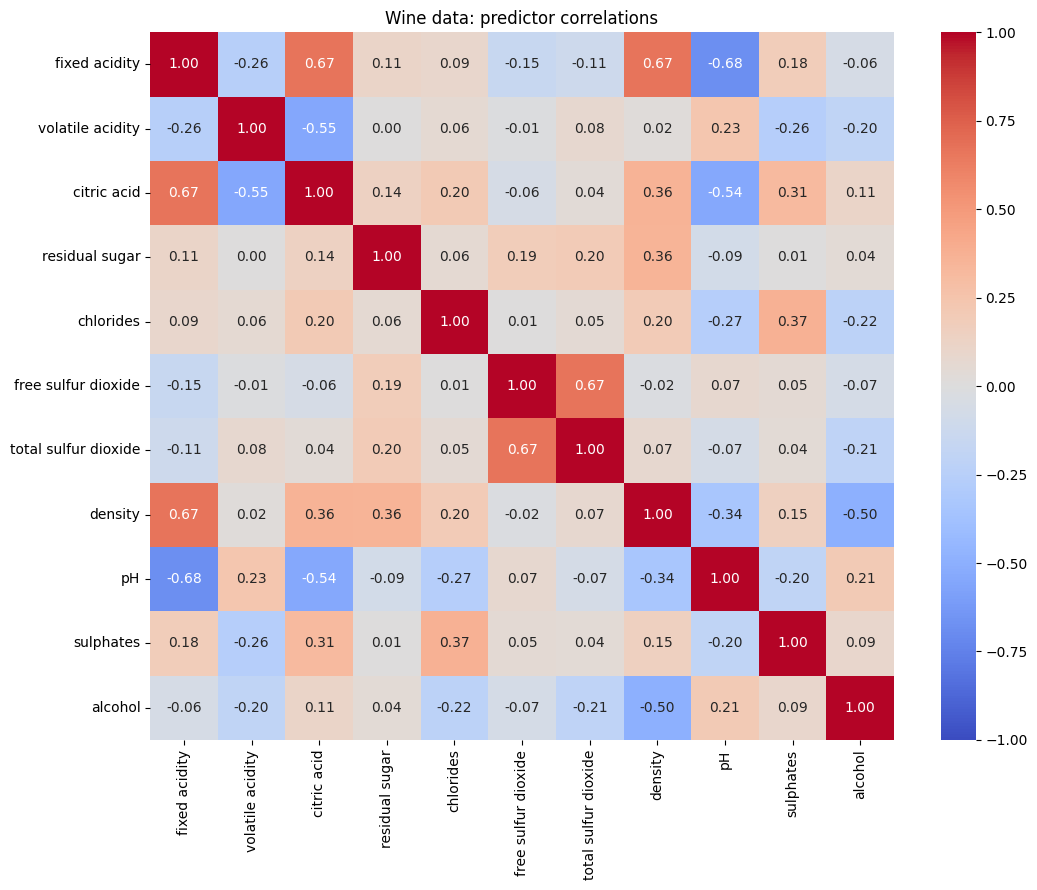

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Separate predictors and target
X = df.drop(columns="quality")
y = df["quality"]

# Calculate predictor correlations
correlation = X.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Wine data: predictor correlations")
plt.tight_layout()
plt.show()

### Step 2. Prepare training and test data

Remove exact duplicate rows. Split observations into 80% training and 20% test data while preserving class proportions. Standardise predictors using training-set means and standard deviations.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Remove exact duplicate rows
data = df.drop_duplicates().reset_index(drop=True)

# Separate predictors and target
X = data.drop(columns="quality")
y = data["quality"]

# Create a stratified training/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Learn scaling parameters from training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Rows after removing duplicates:", len(data))
print("Training shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

print("\nTraining class counts:")
print(y_train.value_counts().sort_index())

print("\nTest class counts:")
print(y_test.value_counts().sort_index())

Rows after removing duplicates: 1359
Training shape: (1087, 11)
Test shape: (272, 11)

Training class counts:
quality
3      8
4     42
5    461
6    428
7    134
8     14
Name: count, dtype: int64

Test class counts:
quality
3      2
4     11
5    116
6    107
7     33
8      3
Name: count, dtype: int64


### Step 3. Baseline Random Forest classifier

Train Random Forest using all 11 predictors. Evaluate test accuracy, balanced accuracy, and macro-F1. Store the baseline results for comparison with reduced representations.

,Model,Inputs,Accuracy,Balanced accuracy,Macro-F1,RF fit time (s)
0,Baseline RF,11,0.588,0.285,0.282,8.251


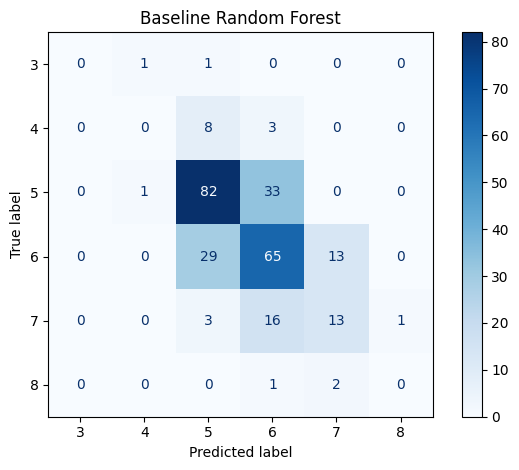

In [ ]:
from time import perf_counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)

# Train the baseline model using all predictors
rf_baseline = RandomForestClassifier(
    n_estimators=300,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

start = perf_counter()
rf_baseline.fit(X_train_scaled, y_train)
baseline_time = perf_counter() - start

# Predict test classes
pred_baseline = rf_baseline.predict(X_test_scaled)

# Store test results
results = pd.DataFrame([{
    "Model": "Baseline RF",
    "Inputs": X_train_scaled.shape[1],
    "Accuracy": accuracy_score(y_test, pred_baseline),
    "Balanced accuracy": balanced_accuracy_score(y_test, pred_baseline),
    "Macro-F1": f1_score(y_test, pred_baseline, average="macro", zero_division=0),
    "RF fit time (s)": baseline_time
}])

display(results.round(3))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_baseline,
    cmap="Blues"
)

plt.title("Baseline Random Forest")
plt.tight_layout()
plt.show()

### Step 4. Principal Component Analysis

Fit PCA to the standardised training predictors. Examine individual and cumulative explained variance. Retain the smallest number of components explaining at least 90% of the training variance, then apply the learned transformation to test data.

,Component,Explained variance,Cumulative variance
0,1,0.287,0.287
1,2,0.172,0.459
2,3,0.143,0.602
3,4,0.110,0.712
4,5,0.086,0.798
5,6,0.058,0.856
6,7,0.054,0.910
7,8,0.038,0.948
8,9,0.031,0.979
9,10,0.016,0.995


Retained components: 7
Retained variance: 0.91
Training shape: (1087, 7)
Test shape: (272, 7)


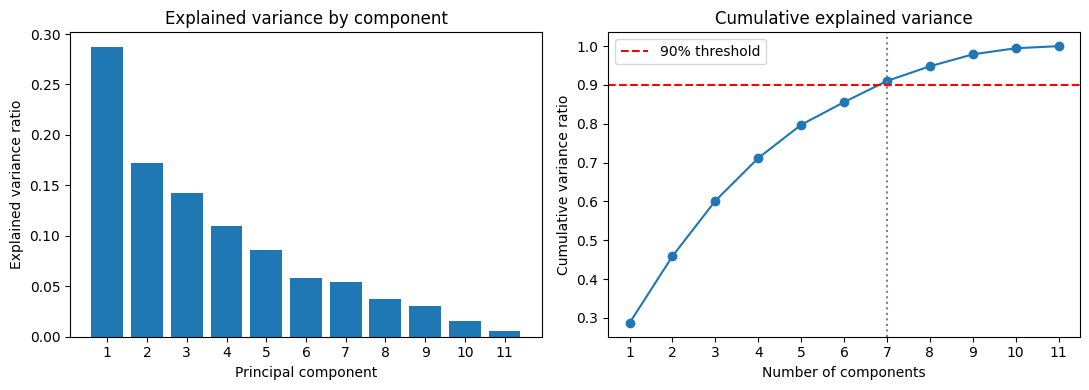

In [18]:
from sklearn.decomposition import PCA
import numpy as np

# Fit PCA using training data only
pca = PCA()
Z_train_all = pca.fit_transform(X_train_scaled)

# Apply the same transformation to test data
Z_test_all = pca.transform(X_test_scaled)

# Calculate individual and cumulative explained variance
variance = pca.explained_variance_ratio_
cumulative = np.cumsum(variance)
components = np.arange(1, len(variance) + 1)

# Retain at least 90% of the training variance
threshold = 0.90
k = np.argmax(cumulative >= threshold) + 1

Z_train = Z_train_all[:, :k]
Z_test = Z_test_all[:, :k]

display(pd.DataFrame({
    "Component": components,
    "Explained variance": variance,
    "Cumulative variance": cumulative
}).round(3))

print("Retained components:", k)
print("Retained variance:", round(cumulative[k - 1], 3))
print("Training shape:", Z_train.shape)
print("Test shape:", Z_test.shape)

# Plot individual and cumulative explained variance
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(components, variance)
axes[0].set_title("Explained variance by component")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_xticks(components)

axes[1].plot(components, cumulative, "o-")
axes[1].axhline(threshold, color="red", linestyle="--", label="90% threshold")
axes[1].axvline(k, color="grey", linestyle=":")
axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative variance ratio")
axes[1].set_xticks(components)
axes[1].legend()

plt.tight_layout()
plt.show()

### Step 5. Random Forest after PCA

Train the same Random Forest classifier using the retained principal components. Evaluate predictions on the unchanged test set and compare the results with the baseline.

,Model,Inputs,Accuracy,Balanced accuracy,Macro-F1,RF fit time (s)
0,Baseline RF,11,0.588,0.285,0.282,8.251
1,PCA + RF,7,0.596,0.288,0.287,5.158


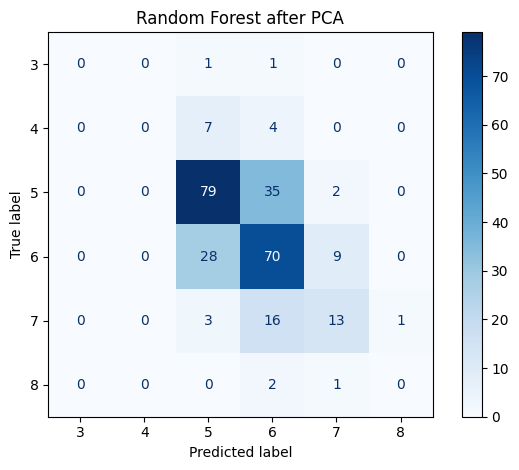

In [ ]:
# Train Random Forest using PCA components
rf_pca = RandomForestClassifier(
    n_estimators=300,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

start = perf_counter()
rf_pca.fit(Z_train, y_train)
pca_time = perf_counter() - start

# Predict test classes
pred_pca = rf_pca.predict(Z_test)

# Store PCA results
pca_result = pd.DataFrame([{
    "Model": "PCA + RF",
    "Inputs": Z_train.shape[1],
    "Accuracy": accuracy_score(y_test, pred_pca),
    "Balanced accuracy": balanced_accuracy_score(y_test, pred_pca),
    "Macro-F1": f1_score(y_test, pred_pca, average="macro", zero_division=0),
    "RF fit time (s)": pca_time
}])

# Replace the previous PCA row if this cell is rerun
results = pd.concat(
    [results[results["Model"] != "PCA + RF"], pca_result],
    ignore_index=True
)

display(results.round(3))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_pca,
    cmap="Blues"
)

plt.title("Random Forest after PCA")
plt.tight_layout()
plt.show()

### Step 6. Feature selection with L1 regularisation

Fit an L1-regularised multinomial logistic model on standardised training predictors. Retain features with a nonzero coefficient for at least one class. Apply the same selected columns to training and test data.

,Feature,Maximum absolute coefficient,Selected
0,fixed acidity,0.1203,True
1,volatile acidity,0.6364,True
2,citric acid,0.0000,False
3,residual sugar,0.0000,False
4,chlorides,0.0456,True
5,free sulfur dioxide,0.0745,True
6,total sulfur dioxide,0.3601,True
7,density,0.0000,False
8,pH,0.0000,False
9,sulphates,0.2079,True


Selected features: ['fixed acidity', 'volatile acidity', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates', 'alcohol']
Retained feature count: 7


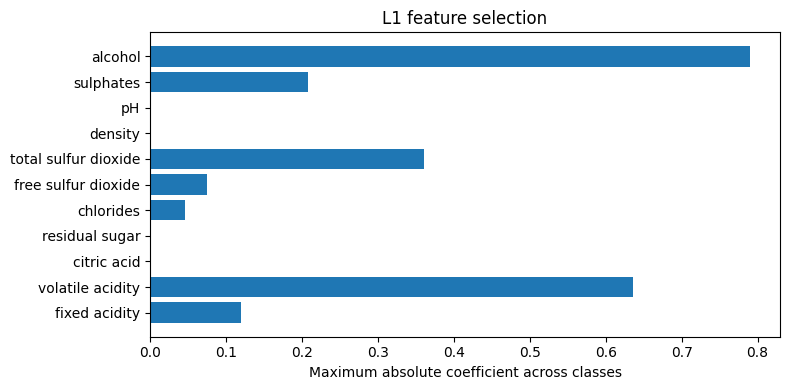

In [19]:
from sklearn.linear_model import LogisticRegression

# Fit an L1-regularised classification model
selector_l1 = LogisticRegression(
    penalty="l1",
    solver="saga",
    C=0.05,
    max_iter=10000,
    random_state=42
)

selector_l1.fit(X_train_scaled, y_train)

# Measure each feature's largest absolute coefficient across classes
importance_l1 = np.max(np.abs(selector_l1.coef_), axis=0)

# Retain features active in at least one class
selected_l1 = importance_l1 > 1e-6
features_l1 = X_train.columns[selected_l1]

# Apply the same feature subset to both datasets
X_train_l1 = X_train_scaled[:, selected_l1]
X_test_l1 = X_test_scaled[:, selected_l1]

# Display coefficients and selection
selection_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Maximum absolute coefficient": importance_l1,
    "Selected": selected_l1
})

display(selection_table.round(4))

print("Selected features:", list(features_l1))
print("Retained feature count:", len(features_l1))

# Plot coefficient magnitudes
plt.figure(figsize=(8, 4))
plt.barh(X_train.columns, importance_l1)
plt.xlabel("Maximum absolute coefficient across classes")
plt.title("L1 feature selection")
plt.tight_layout()
plt.show()

### Step 7. Random Forest after L1 feature selection

Train Random Forest using the selected original predictors. Keep the classifier settings and test observations unchanged. Compare performance with the baseline and PCA pipelines.

,Model,Inputs,Accuracy,Balanced accuracy,Macro-F1,RF fit time (s)
0,Baseline RF,11,0.588,0.285,0.282,8.251
1,PCA + RF,7,0.596,0.288,0.287,5.158
2,Elastic Net selection + RF,6,0.607,0.316,0.331,3.569
3,L1 selection + RF,7,0.618,0.296,0.291,2.836


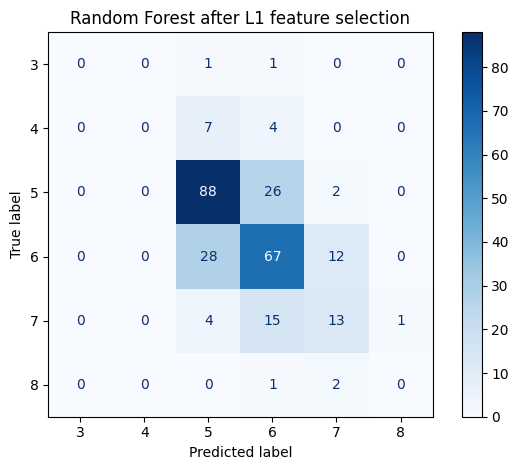

In [20]:
# Train Random Forest using L1-selected features
rf_l1 = RandomForestClassifier(
    n_estimators=300,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

start = perf_counter()
rf_l1.fit(X_train_l1, y_train)
l1_time = perf_counter() - start

# Predict test classes
pred_l1 = rf_l1.predict(X_test_l1)

# Store evaluation results
l1_result = pd.DataFrame([{
    "Model": "L1 selection + RF",
    "Inputs": X_train_l1.shape[1],
    "Accuracy": accuracy_score(y_test, pred_l1),
    "Balanced accuracy": balanced_accuracy_score(y_test, pred_l1),
    "Macro-F1": f1_score(y_test, pred_l1, average="macro", zero_division=0),
    "RF fit time (s)": l1_time
}])

# Update the comparison table
results = pd.concat(
    [results[results["Model"] != "L1 selection + RF"], l1_result],
    ignore_index=True
)

display(results.round(3))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_l1,
    cmap="Blues"
)

plt.title("Random Forest after L1 feature selection")
plt.tight_layout()
plt.show()

### Step 8. Feature selection with Elastic Net

Fit an Elastic Net-regularised multinomial logistic model. Combine L1 sparsity with L2 shrinkage. Retain predictors with a nonzero coefficient for at least one class.

,Feature,Maximum absolute coefficient,Selected
0,fixed acidity,0.0173,True
1,volatile acidity,0.2773,True
2,citric acid,0.0676,True
3,residual sugar,0.0000,False
4,chlorides,0.0000,False
5,free sulfur dioxide,0.0000,False
6,total sulfur dioxide,0.2463,True
7,density,0.0000,False
8,pH,0.0000,False
9,sulphates,0.1433,True


Selected features: ['fixed acidity', 'volatile acidity', 'citric acid', 'total sulfur dioxide', 'sulphates', 'alcohol']
Retained feature count: 6


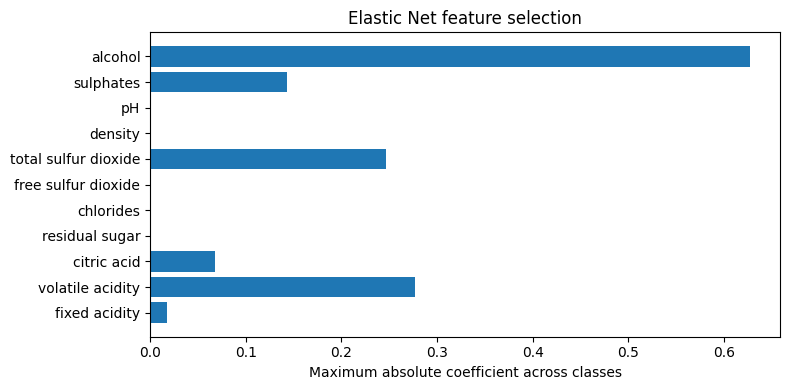

In [ ]:
# Set the regularisation parameters
C_en = 0.015
mixing_ratio = 0.5

# Fit an Elastic Net classification model
selector_en = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    C=C_en,
    l1_ratio=mixing_ratio,
    max_iter=10000,
    random_state=42
)

selector_en.fit(X_train_scaled, y_train)

# Measure coefficient magnitudes across classes
importance_en = np.max(np.abs(selector_en.coef_), axis=0)

# Select active features
selected_en = importance_en > 1e-6
features_en = X_train.columns[selected_en]

# Apply the same subset to training and test data
X_train_en = X_train_scaled[:, selected_en]
X_test_en = X_test_scaled[:, selected_en]

# Display the selection results
selection_table_en = pd.DataFrame({
    "Feature": X_train.columns,
    "Maximum absolute coefficient": importance_en,
    "Selected": selected_en
})

display(selection_table_en.round(4))

print("Selected features:", list(features_en))
print("Retained feature count:", len(features_en))

# Plot coefficient magnitudes
plt.figure(figsize=(8, 4))
plt.barh(X_train.columns, importance_en)
plt.xlabel("Maximum absolute coefficient across classes")
plt.title("Elastic Net feature selection")
plt.tight_layout()
plt.show()

### Step 9. Random Forest after Elastic Net feature selection

Train Random Forest using the predictors selected by Elastic Net. Evaluate on the unchanged test set and compare all four predictive pipelines.

,Model,Inputs,Accuracy,Balanced accuracy,Macro-F1,RF fit time (s)
0,Baseline RF,11,0.588,0.285,0.282,8.251
1,PCA + RF,7,0.596,0.288,0.287,5.158
2,L1 selection + RF,7,0.618,0.296,0.291,4.823
3,Elastic Net selection + RF,6,0.607,0.316,0.331,3.569


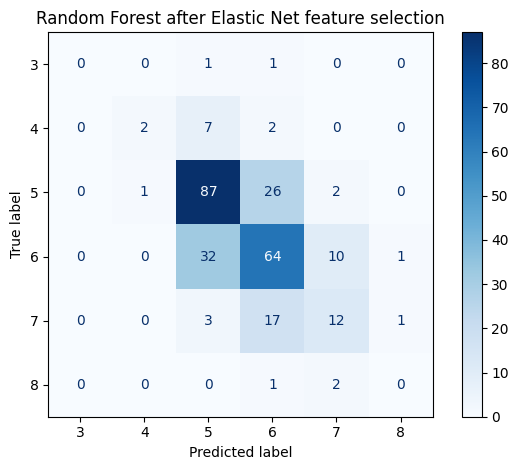

In [ ]:
# Train Random Forest using Elastic Net-selected features
rf_en = RandomForestClassifier(
    n_estimators=300,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

start = perf_counter()
rf_en.fit(X_train_en, y_train)
en_time = perf_counter() - start

# Predict test classes
pred_en = rf_en.predict(X_test_en)

# Store evaluation results
en_result = pd.DataFrame([{
    "Model": "Elastic Net selection + RF",
    "Inputs": X_train_en.shape[1],
    "Accuracy": accuracy_score(y_test, pred_en),
    "Balanced accuracy": balanced_accuracy_score(y_test, pred_en),
    "Macro-F1": f1_score(y_test, pred_en, average="macro", zero_division=0),
    "RF fit time (s)": en_time
}])

# Update the comparison table
results = pd.concat(
    [results[results["Model"] != "Elastic Net selection + RF"], en_result],
    ignore_index=True
)

display(results.round(3))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_en,
    cmap="Blues"
)

plt.title("Random Forest after Elastic Net feature selection")
plt.tight_layout()
plt.show()

### Step 10. Visual exploration with PCA and t-SNE

Visualise the same training observations using PCA and t-SNE. Colour points by quality class. Compare t-SNE perplexities while keeping the other settings fixed.

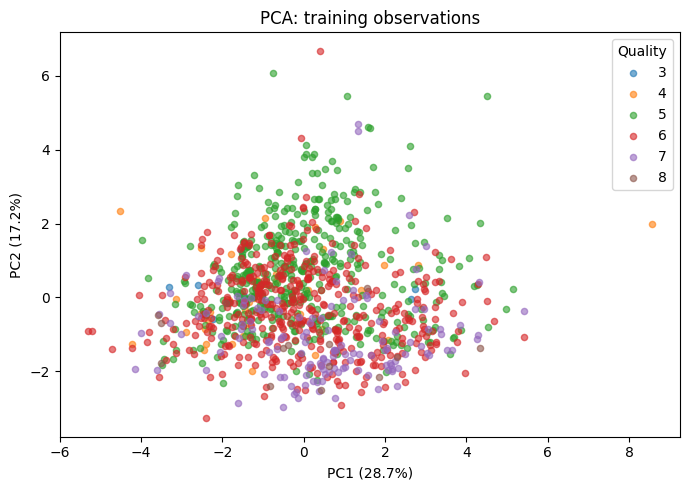

In [ ]:
# Plot the first two principal components
plt.figure(figsize=(7, 5))

for quality in sorted(y_train.unique()):
    mask = y_train.to_numpy() == quality

    plt.scatter(
        Z_train_all[mask, 0],
        Z_train_all[mask, 1],
        label=str(quality),
        s=20,
        alpha=0.6
    )

plt.xlabel(f"PC1 ({100 * variance[0]:.1f}%)")
plt.ylabel(f"PC2 ({100 * variance[1]:.1f}%)")
plt.title("PCA: training observations")
plt.legend(title="Quality")
plt.tight_layout()
plt.show()

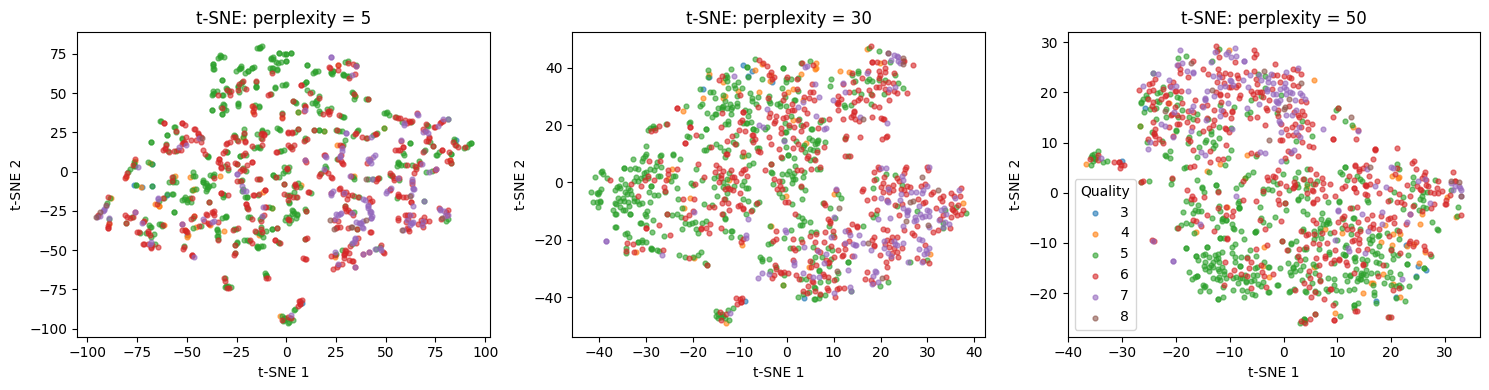

In [ ]:
from sklearn.manifold import TSNE

# Compare neighbourhood scales using the same observations
perplexities = [5, 30, 50]
tsne_embeddings = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, perplexity in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate=200,
        random_state=42
    )

    embedding = tsne.fit_transform(X_train_scaled)
    tsne_embeddings[perplexity] = embedding

    for quality in sorted(y_train.unique()):
        mask = y_train.to_numpy() == quality

        ax.scatter(
            embedding[mask, 0],
            embedding[mask, 1],
            label=str(quality),
            s=12,
            alpha=0.6
        )

    ax.set_title(f"t-SNE: perplexity = {perplexity}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

axes[-1].legend(title="Quality")
plt.tight_layout()
plt.show()

### Step 11. Random-seed sensitivity of t-SNE

Compare two t-SNE embeddings with identical settings and different random seeds. Examine whether neighbourhood patterns persist.

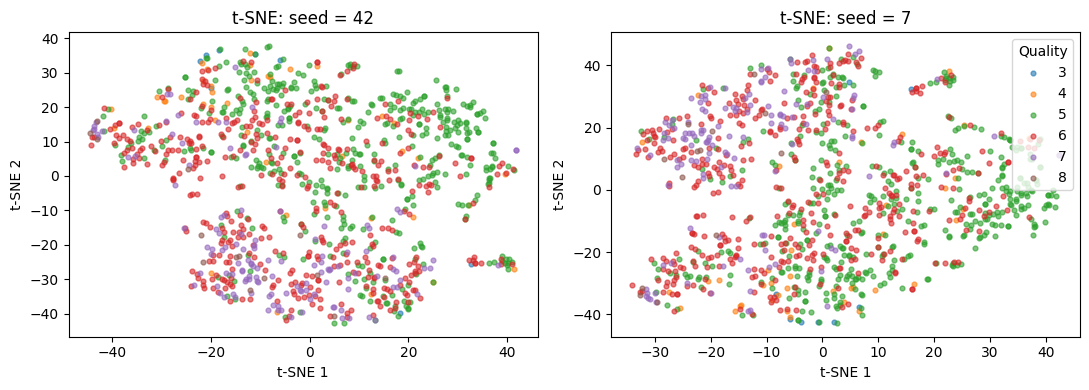

In [ ]:
# Repeat the perplexity-30 embedding with another seed
embedding_seed7 = TSNE(
    n_components=2,
    perplexity=30,
    init="random",
    learning_rate=200,
    random_state=7
).fit_transform(X_train_scaled)

# Use random initialisation for both seeds in this comparison
embedding_seed42 = TSNE(
    n_components=2,
    perplexity=30,
    init="random",
    learning_rate=200,
    random_state=42
).fit_transform(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, embedding, seed in zip(
    axes,
    [embedding_seed42, embedding_seed7],
    [42, 7]
):
    for quality in sorted(y_train.unique()):
        mask = y_train.to_numpy() == quality
        ax.scatter(
            embedding[mask, 0], embedding[mask, 1],
            label=str(quality), s=12, alpha=0.6
        )

    ax.set_title(f"t-SNE: seed = {seed}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

axes[-1].legend(title="Quality")
plt.tight_layout()
plt.show()

### Step 12. UMAP parameter comparison

Embed the standardised training predictors in two dimensions. Compare neighbourhood sizes and minimum distances using the same observations and random seed.

In [ ]:
%pip install -q umap-learn

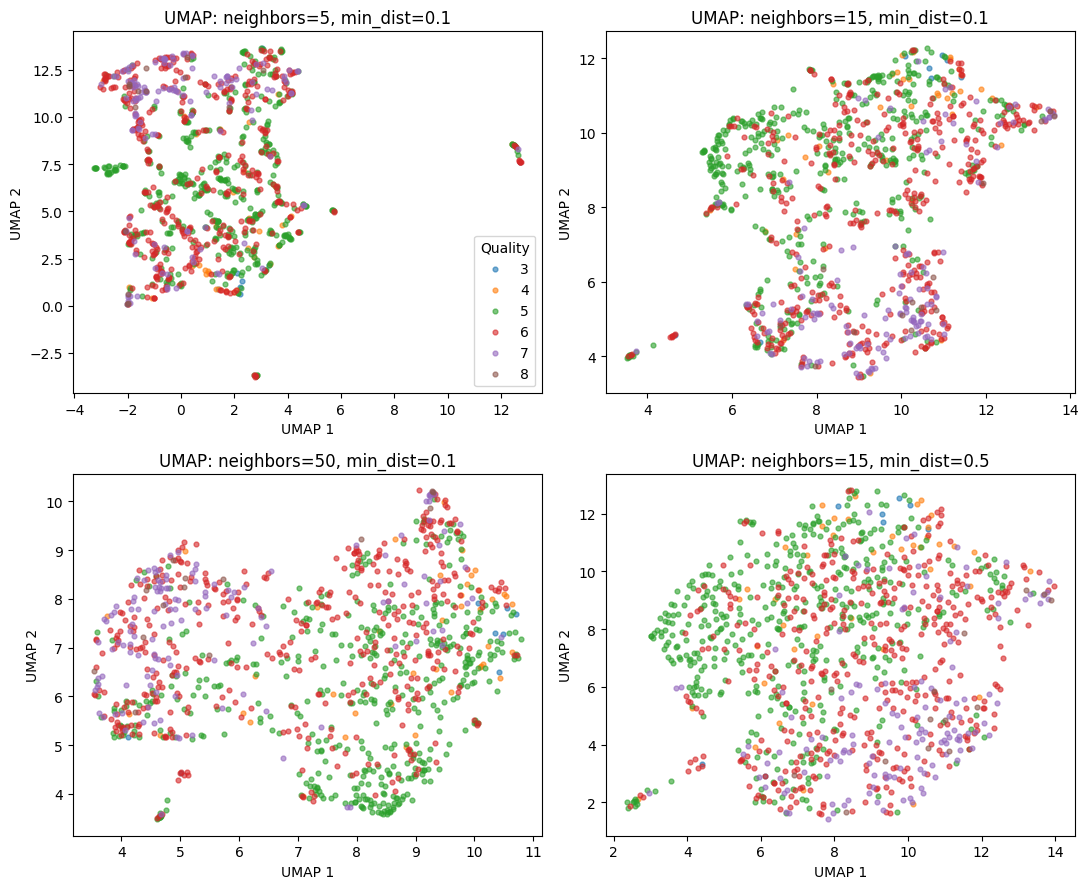

In [ ]:
from umap import UMAP

# Compare neighbourhood size and minimum distance
settings = [(5, 0.1), (15, 0.1), (50, 0.1), (15, 0.5)]
umap_embeddings = {}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (neighbors, distance) in zip(axes.flat, settings):
    embedding = UMAP(
        n_components=2,
        n_neighbors=neighbors,
        min_dist=distance,
        metric="euclidean",
        random_state=42,
        n_jobs=1
    ).fit_transform(X_train_scaled)

    umap_embeddings[(neighbors, distance)] = embedding

    for quality in sorted(y_train.unique()):
        mask = y_train.to_numpy() == quality
        ax.scatter(
            embedding[mask, 0], embedding[mask, 1],
            label=str(quality), s=12, alpha=0.6
        )

    ax.set_title(f"UMAP: neighbors={neighbors}, min_dist={distance}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

axes[0, 0].legend(title="Quality")
plt.tight_layout()
plt.show()